<a href="https://colab.research.google.com/github/JannatLima/Heart_Disease_Applied_ML/blob/main/Heart_Disease_Applied_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import os

print(os.listdir("/content"))


['.config', 'WARNING', 'processed.hungarian.data', 'switzerland.data', 'processed.cleveland.data', 'ask-detrano', 'processed.va.data', 'Index', 'new.data', 'reprocessed.hungarian.data', 'heart-disease.names', 'long-beach-va.data', 'cleve.mod', 'processed.switzerland.data', 'cleveland.data', 'bak', 'hungarian.data', 'sample_data']


In [2]:

import pandas as pd

# Define the 14 column names
columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

# Load the processed Cleveland dataset
file_path = "/content/processed.cleveland.data"

df = pd.read_csv(
    file_path,
    header=None,
    names=columns,
    na_values="?"
)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()


Dataset loaded successfully!
Number of rows: 303
Number of columns: 14


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:

print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nHeart disease target distribution:")
print(df["num"].value_counts(dropna=False).sort_index())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Missing values in each column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          

In [4]:

# Create a binary target:
# 0 = no heart disease recorded
# 1 = heart disease recorded

df["target"] = (df["num"] > 0).astype(int)

print("New target distribution:")
print(df["target"].value_counts())

print("\nTarget proportions:")
print(df["target"].value_counts(normalize=True).round(3))


New target distribution:
target
0    164
1    139
Name: count, dtype: int64

Target proportions:
target
0    0.541
1    0.459
Name: proportion, dtype: float64


In [5]:

# Input features: exclude the original and new target columns
X = df.drop(columns=["num", "target"])

# Output we want the model to predict
y = df["target"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature names:")
print(X.columns.tolist())


Feature matrix shape: (303, 13)
Target shape: (303,)

Feature names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [6]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).round(3))


Training records: 242
Testing records: 61

Training target proportions:
target
0    0.541
1    0.459
Name: proportion, dtype: float64

Testing target proportions:
target
0    0.541
1    0.459
Name: proportion, dtype: float64


In [7]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train using only the training data
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [8]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predictions for unseen test records
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.869
ROC-AUC: 0.951

Classification report:
              precision    recall  f1-score   support

           0       0.93      0.82      0.87        33
           1       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61

Confusion matrix:
[[27  6]
 [ 2 26]]


In [9]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Create the Random Forest pipeline
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions on the test data
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("Random Forest Accuracy:",
      round(accuracy_score(y_test, rf_pred), 3))

print("Random Forest ROC-AUC:",
      round(roc_auc_score(y_test, rf_prob), 3))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))


Random Forest Accuracy: 0.902
Random Forest ROC-AUC: 0.95

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.88      0.91        33
           1       0.87      0.93      0.90        28

    accuracy                           0.90        61
   macro avg       0.90      0.90      0.90        61
weighted avg       0.90      0.90      0.90        61

Confusion Matrix:
[[29  4]
 [ 2 26]]


In [10]:

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

print(results.round(3).to_string(index=False))


              Model  Accuracy  ROC-AUC
Logistic Regression     0.869    0.951
      Random Forest     0.902    0.950


Random Forest Feature Importance:
 Feature  Importance
    thal      0.1718
      cp      0.1270
 thalach      0.1157
      ca      0.1154
 oldpeak      0.0892
     age      0.0811
    chol      0.0686
trestbps      0.0639
   exang      0.0587
   slope      0.0419
     sex      0.0409
 restecg      0.0183
     fbs      0.0076


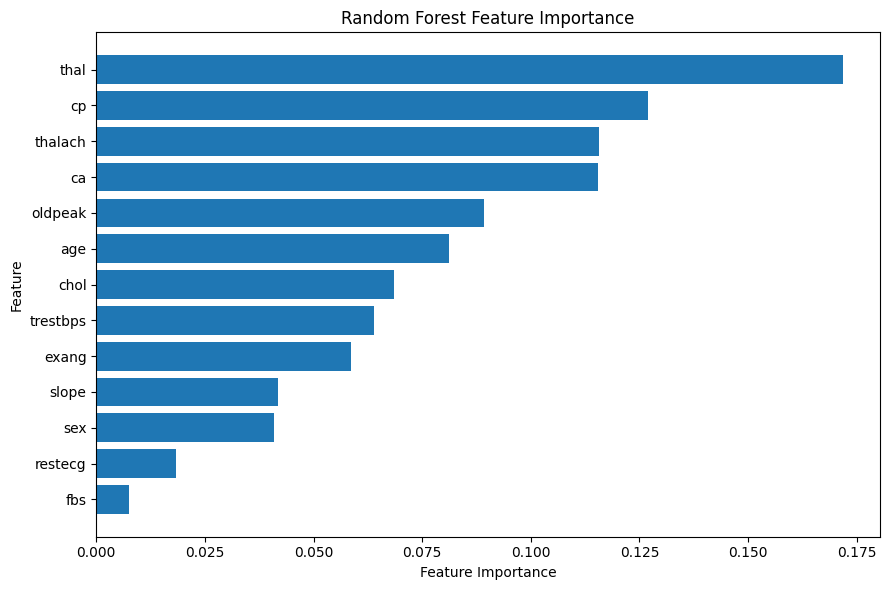

In [11]:

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from the trained Random Forest
rf_classifier = rf_model.named_steps["classifier"]

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_classifier.feature_importances_
})

# Sort from most important to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Random Forest Feature Importance:")
print(importance_df.round(4).to_string(index=False))

# Visualize the results
plt.figure(figsize=(9, 6))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
